<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>


# DATA/MSML 641: Natural Language Processing
## Session 12: Frontier NLP: Agents, Multimodal and Beyond

**University of Maryland, College Park**
**Fall 2026**
**Instructor**: Armin Mehrabian
**Date**: November 24, 2026

## Learning Objectives

This session is a map, not a deep dive.
By the end you should be able to place each of these ideas and say in one or two sentences what problem it solves.

1. Name what changed in the transformer between 2017 and today, and why each change was made
2. Explain why running an LLM is mostly limited by memory, not arithmetic
3. Describe the two phases of generation, prefill and decode, and what the KV cache does between them
4. Name the main tricks for serving models fast and cheaply: quantization, batching, paged attention, speculative decoding
5. Explain test-time compute and how it connects to chain-of-thought
6. Describe what makes an agent, what MCP standardizes, and how vision language models take in images
7. Reason about where bias enters an NLP system and who carries the cost of errors

## Where we have been

Sessions 1 to 11 built the stack from the bottom:

- Words and meaning, sequences, evaluation
- Distributed representations, neural networks, transformers
- Language models and post-training
- Retrieval, and structure through graphs

Session 7 gave you the 2017 transformer.
Almost every production model since has kept self-attention and changed nearly everything around it.

Today: what those changes are, what it takes to run these models, and what gets built on top.

## The map for today

```
 PART I     The modern transformer     what changed inside the model since 2017
 PART II    Hardware                   why memory, not arithmetic, sets the speed
 PART III   Inference and serving      prefill, decode, the KV cache, and the tricks
 PART IV    Test-time compute          spending more compute on the answer, not the model
 PART V     Agents and tools           from one call to a loop; MCP
 PART VI    Multimodal                 images as tokens
 PART VII   Bias and ethics            who carries the errors
```

Each part is a few slides.
You are not expected to implement any of this.
You are expected to know where each idea sits and what problem it solves.

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part I: The Modern Transformer

The core of Session 7 still holds.
This part covers what was swapped out around it, and why.

# What changed since 2017

| Component | Original (2017) | Typical today | Why it changed |
|---|---|---|---|
| **Attention** | Multi-head (MHA) | Grouped-query (GQA) + Flash Attention | Smaller KV cache, less memory traffic |
| **Position** | Sinusoidal or learned absolute | RoPE | Works better at long and unseen lengths |
| **Normalization** | Post-LayerNorm | Pre-norm with RMSNorm | Trains more stably, slightly cheaper |
| **FFN activation** | ReLU | SwiGLU | Better quality for the same compute |
| **FFN layout** | One dense FFN | Mixture of Experts | More parameters without more compute per token |
| **Precision** | FP32 | BF16 training, FP8 and INT4 at inference | Less memory, faster math |

Self-attention is still there.
Almost every other row was replaced.

# Small changes inside the block: RMSNorm and SwiGLU

**Pre-norm.** Session 7 discussed where the norm goes.
Modern models put it *before* attention and before the FFN, so the residual stream itself is never normalized.
Deep stacks train more stably this way.

**RMSNorm** drops the mean subtraction from LayerNorm and only rescales:

$$\text{RMSNorm}(x) = \frac{x}{\sqrt{\frac{1}{d}\sum_i x_i^2 + \epsilon}} \odot g$$

Fewer operations, same quality in practice.

**SwiGLU** replaces the ReLU in the FFN with a gated unit:

$$\text{FFN}(x) = W_2\,\big(\text{SiLU}(W_1 x) \odot W_3 x\big)$$

One branch decides how much of the other branch passes through.
Small, consistent quality gain, which is why nearly every recent model uses it.

You do not need to memorize these. Recognize the names when you read a model card.

# Grouped-Query Attention (GQA) and Multi-Query Attention (MQA)

In multi-head attention, every head has its own K and V.
At inference those K and V vectors are stored for every past token (the KV cache, Part III), and that storage grows large.

**Idea:** let several query heads share one set of K and V.

| Variant | Query heads | K/V heads | Used in |
|---|---|---|---|
| **MHA** | 32 | 32 | Original transformer, GPT-2 |
| **GQA** | 32 | 8 (groups of 4 share) | Llama 2 70B, Llama 3, Mistral, Gemma |
| **MQA** | 32 | 1 (all share) | PaLM, StarCoder |

**GQA** keeps nearly all of MHA's quality and cuts the KV cache several times over.
It is the default in most open models today.

# Mixture of Experts (MoE)

**Idea:** replace each FFN with many smaller "expert" FFNs and a small **router** that picks the top-k experts for each token.

```
 token ──► router ──► picks 2 of 8 experts ──► weighted sum of their outputs
```

The model *stores* a lot of parameters but only *uses* a few per token.

| Model | Total parameters | Active per token | Experts (active) |
|---|---|---|---|
| Mixtral 8x7B | 46.7B | about 13B | 8 (2) |
| DeepSeek-V3 | 671B | about 37B | 256 (8) |

**The trade:** compute per token follows the *active* parameters, but memory follows the *total*.
An MoE model is cheap to run per token and expensive to fit on GPUs.

Most frontier models are now believed to be MoE.

# Beyond attention: State Space Models and Mamba

Attention compares every token with every earlier token: cost grows with the square of length, and the KV cache grows with length.

**State space models** carry a fixed-size state forward, like an RNN, but are designed so training still runs in parallel.

**Mamba** (Gu and Dao, 2023) made the state update depend on the input, which made SSMs competitive with transformers on language.

| | Transformer | SSM / Mamba |
|---|---|---|
| Cost in sequence length | Quadratic | Linear |
| Memory at inference | Grows with context (KV cache) | Fixed |
| Exact recall of something far back | Strong | Weaker |

**Where it landed:** hybrids.
Models such as Jamba mix a few attention layers in with many Mamba layers, keeping recall where it is needed and saving memory elsewhere.

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part II: Hardware

To understand why so many of these changes exist, you need one fact about GPUs:
moving numbers costs far more than multiplying them.

# A GPU in one slide

A GPU has two kinds of memory:

- **On-chip memory (SRAM):** tiny, right next to the arithmetic units, very fast
- **Main GPU memory (HBM):** large (around 80 GB), but much slower to reach

The arithmetic units are so fast that they usually wait on data.
Roughly: the GPU could do **hundreds of multiplications** in the time it takes to fetch one number from main memory.

So the question for speed is usually not "how much math?" but "how many times do we read from main memory?"

# Busy or waiting?

**Many tokens at once** (training, reading your prompt): each weight is fetched once and used for many tokens. The GPU stays busy doing math.

**One token at a time** (writing the answer): each weight is fetched to do a single multiply. The GPU mostly waits on memory.

| Work | GPU is mostly |
|---|---|
| Training | Busy computing |
| Reading the prompt | Busy computing |
| Writing the answer, one token at a time | Waiting on memory |

Keep this one idea. It explains Flash Attention, the KV cache, batching, quantization, and speculative decoding.

# Flash Attention: same math, fewer trips to memory

Standard attention writes the full $N \times N$ score matrix to main GPU memory and reads it back several times.
For long inputs, those trips dominate the run time.

**Flash Attention** (Dao et al., 2022) works on small tiles that fit in fast on-chip memory, so the full matrix is never written out.

- **Exact**: same output as Session 7's attention. Nothing approximated
- 2 to 4 times faster, and makes long context windows practical

A systems trick, not a new model.

# Precision and quantization

Each parameter is stored with some number of bits.
Fewer bits: less memory to hold the model, and less to read for every token.

| Format | Bytes per parameter | 70B model weights |
|---|---|---|
| FP32 | 4 | 280 GB |
| BF16 | 2 | 140 GB (the usual default) |
| FP8 / INT8 | 1 | 70 GB |
| INT4 | 0.5 | 35 GB |

**Quantization** shrinks a trained model to fewer bits.
8 bits usually costs little quality. 4 bits is often fine and is how people run large models on one GPU or a laptop.

In [1]:
# How much memory does a model need just for its weights?
models = {"Llama 3 8B": 8e9, "Llama 3 70B": 70e9, "DeepSeek-V3 (total)": 671e9}
formats = {"FP32": 4, "BF16": 2, "FP8/INT8": 1, "INT4": 0.5}

print(f"{'model':<22}" + "".join(f"{f:>10}" for f in formats))
for name, params in models.items():
    row = "".join(f"{params * b / 1e9:>8.0f}GB" for b in formats.values())
    print(f"{name:<22}{row}")

print("\nAn H100 has 80 GB. Anything above that needs several GPUs or fewer bits.")

model                       FP32      BF16  FP8/INT8      INT4
Llama 3 8B                  32GB      16GB       8GB       4GB
Llama 3 70B                280GB     140GB      70GB      35GB
DeepSeek-V3 (total)       2684GB    1342GB     671GB     336GB

An H100 has 80 GB. Anything above that needs several GPUs or fewer bits.


# When one GPU is not enough

Big models are split across many GPUs:

- **Data parallel:** every GPU has the whole model and works on different examples
- **Tensor parallel:** each big matrix is cut into pieces across GPUs
- **Pipeline parallel:** different layers on different GPUs

The cost is that GPUs have to talk to each other, so the connections between them matter too.

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part III: Inference and Serving

Training happens once. Inference happens billions of times.
Most of the engineering effort in LLMs today is here.

# The life of a request

```
 prompt (2,000 tokens)
     │
     ▼
 PREFILL   run all 2,000 prompt tokens through the model at once
     │     compute-bound, parallel, like training
     │     writes K and V for every prompt token  ──►  KV CACHE
     ▼                                                    │
 first output token                                       │
     │                                                    │
     ▼                                                    │
 DECODE    run ONE new token through the model  ◄─────────┘ reads all past K and V
     │     memory-bound: reads every weight for one token
     │     appends its own K and V to the cache
     ▼
 next token ... repeat until a stop token or the length limit
```

# Prefill vs decode

| | Prefill | Decode |
|---|---|---|
| Tokens processed per step | All prompt tokens at once | One |
| Bound by | Compute | Memory bandwidth |
| GPU utilization | High | Low unless requests are batched |
| What the user feels | **Time to first token (TTFT)** | **Time per output token**, or tokens per second |

**Why this matters to you:**

- A long prompt makes you wait before anything appears (prefill).
- A long answer makes you watch it stream slowly (decode).
- Many APIs charge several times more per output token than per input token. Decode is the expensive phase.

In [2]:
# Upper bound on decode speed for ONE request: every step reads every weight once
hbm_bandwidth = 3.35e12   # bytes per second, H100

for name, params, bytes_per in [("8B, BF16", 8e9, 2), ("8B, INT4", 8e9, 0.5), ("70B, BF16", 70e9, 2)]:
    bytes_per_token = params * bytes_per
    print(f"{name:<10}  at most {hbm_bandwidth / bytes_per_token:6.0f} tokens per second")

print("\nThe 70B row is optimistic: its weights do not even fit on one 80 GB GPU.")
print("Quantization speeds up decode mainly because there are fewer bytes to read.")

8B, BF16    at most    209 tokens per second
8B, INT4    at most    838 tokens per second
70B, BF16   at most     24 tokens per second

The 70B row is optimistic: its weights do not even fit on one 80 GB GPU.
Quantization speeds up decode mainly because there are fewer bytes to read.


# The KV cache

In decode, the new token attends to every earlier token, so it needs every earlier K and V.
Recomputing them each step would redo the whole prefill every time.
Instead they are kept in memory: the **KV cache**.

$$\text{KV cache bytes} = 2 \times n_{\text{layers}} \times n_{\text{kv heads}} \times d_{\text{head}} \times n_{\text{tokens}} \times \text{bytes per value}$$

For a Llama 3 70B style model (80 layers, 8 KV heads, head size 128, BF16), that is about **0.3 MB per token**.
At 128K tokens: about **40 GB, for one request**.

The cache, not the weights, often decides how many users one GPU can serve and how long the context can be.

Ways to shrink it: **GQA and MQA** (fewer K/V heads), **quantizing the cache** to 8 or 4 bits, **sliding window** attention (keep only recent tokens in some layers).

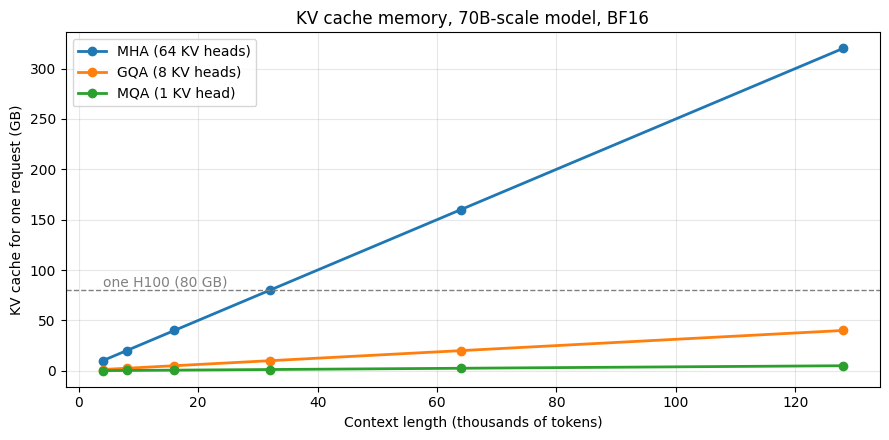

MHA (64 KV heads)  at 128K tokens:  320.0 GB
GQA (8 KV heads)   at 128K tokens:   40.0 GB
MQA (1 KV head)    at 128K tokens:    5.0 GB


In [3]:
# KV cache size: MHA vs GQA vs MQA, for a 70B-scale model in BF16
import matplotlib.pyplot as plt

def kv_cache_gb(n_layers, n_kv_heads, d_head, seq_len, bytes_per=2):
    return 2 * n_layers * n_kv_heads * d_head * seq_len * bytes_per / 1024**3

n_layers, d_head = 80, 128
seq_lengths = [4096, 8192, 16384, 32768, 65536, 131072]
configs = {"MHA (64 KV heads)": 64, "GQA (8 KV heads)": 8, "MQA (1 KV head)": 1}

fig, ax = plt.subplots(figsize=(9, 4.5))
for label, n_kv in configs.items():
    ax.plot([s // 1024 for s in seq_lengths],
            [kv_cache_gb(n_layers, n_kv, d_head, s) for s in seq_lengths], "o-", label=label, linewidth=2)
ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.text(4, 84, "one H100 (80 GB)", color="gray")
ax.set_xlabel("Context length (thousands of tokens)")
ax.set_ylabel("KV cache for one request (GB)")
ax.set_title("KV cache memory, 70B-scale model, BF16")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for label, n_kv in configs.items():
    print(f"{label:<18} at 128K tokens: {kv_cache_gb(n_layers, n_kv, d_head, 131072):6.1f} GB")

# Serving many users at once: batching

Decode for one user wastes the GPU: it reads every weight to do one multiply per weight.
Decode for 64 users at once reads the weights **once** and does 64 multiplies per weight.
The same memory traffic now serves 64 people. Same idea as "busy or waiting" in Part II.

**Static batching:** wait for a batch, run it until the longest answer finishes. Short answers sit idle.

**Continuous batching:** after every decode step, finished requests leave and new ones join.
The GPU stays full. This is the standard in modern serving systems.

The limit is memory: every request in the batch brings its own KV cache.

# Paged attention and prefix caching

**Problem:** a request's KV cache grows one token at a time, to an unknown final length.
Reserving the maximum length up front wastes most of the memory.

**Paged attention** (vLLM, Kwon et al., 2023) stores the cache in small fixed-size blocks, like pages in an operating system, allocated as the answer grows.
Much less waste means more requests fit in a batch, which means more throughput.

**Prefix caching:** many requests start with the same text, such as a long system prompt or the same document.
Keep the KV cache for that shared prefix and reuse it, so prefill is skipped for the repeated part.
This is why some APIs charge less for cached input tokens.

Open-source engines that do all of this: **vLLM**, **SGLang**, **TensorRT-LLM**, **llama.cpp** (for laptops).

# Speculative decoding

Decode is memory-bound, so checking several tokens in one forward pass costs about the same as generating one.

1. A small, fast **draft model** guesses the next $k$ tokens
2. The large **target model** checks all $k$ in **one** forward pass, like a mini prefill
3. Keep the guesses up to the first one the target disagrees with, and take the target's token there
4. Repeat

With the right acceptance rule, the output follows **exactly** the same distribution as the target model alone. No quality loss.

Typical speedup: 2 to 3 times, depending on how often the draft guesses right.

Variants: Medusa (extra prediction heads on the target), EAGLE (drafts from the target's own features), self-speculative decoding (early layers as the draft).

# Part III recap: one table

| Technique | Problem it solves | Phase |
|---|---|---|
| KV cache | Recomputing past K and V every step | Decode |
| GQA / MQA | KV cache too large | Decode |
| Flash Attention | Memory traffic of the $N \times N$ matrix | Prefill and training |
| Quantization | Weights too large, too many bytes per step | Decode, fitting the model |
| Continuous batching | GPU idle during single-user decode | Decode |
| Paged attention | Memory wasted reserving KV space | Decode |
| Prefix caching | Repeating prefill for the same prompt start | Prefill |
| Speculative decoding | One token per expensive step | Decode |

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part IV: Test-Time Compute

Until recently, the way to a better model was a bigger model or more data.
Now there is a third option: let the model think longer.

# Chain-of-thought, and what it is not

Asking for intermediate steps improves accuracy on multi-step problems.

What it is: a way of spending more forward passes on a harder problem.
Each reasoning token is one more decode step the model gets to use.

What it is not: a faithful account of how the model reached the answer.
A model can produce a correct chain and a wrong answer, or a wrong chain and a right answer.

> Reading: Wei et al., *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models*

# Test-time compute scaling

**Reasoning models** are trained, mostly with reinforcement learning, to produce long chains of reasoning before answering.
Examples: OpenAI o1 and o3, DeepSeek-R1, Claude with extended thinking.

Other ways to spend compute at answer time:

- Sample several answers and take a majority vote
- Generate many candidates and let a verifier or reward model pick one
- Search over partial solutions

**Finding** (Snell et al., 2024): on hard reasoning problems, extra compute at answer time can beat a model several times larger.

**DeepSeek-R1** (2025) showed long reasoning can emerge from reinforcement learning on problems with checkable answers.

**Connect to Part III:** every reasoning token is a decode step.
Thinking longer means more of the expensive, memory-bound phase, which is why fast decoding matters even more now.

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part V: Agents and Tools

So far: one prompt in, one answer out.
An agent puts the model inside a loop that can act on the world.

# From one call to a loop

A single model call maps a prompt to a completion.
An agent adds a loop: the model chooses an action, something in the world runs it, the result comes back, and the model chooses again.

The three things that make it an agent:

- **Tools**: it can do something other than emit text
- **A loop**: the output of one step becomes the input to the next
- **A stopping condition**: it decides when it is done

| | Control flow | Good when |
|---|---|---|
| **Workflow** | You write it | The steps are known in advance |
| **Agent** | The model decides | The steps depend on what is found along the way |

Most production systems are workflows.
Agents cost more, fail in stranger ways, and are harder to evaluate.

> Reading: Anthropic, *Building Effective Agents*

# ReAct: reason and act

Interleave a reasoning trace with actions:

```
Thought:     I need the population of Maryland
Action:      search("Maryland population 2026")
Observation: 6.2 million
Thought:     Now I need the figure for Virginia
...
```

The trace is what lets the model recover from a bad observation.

**Cost note from Part III:** every observation is appended to the context, so each step adds prefill, and the KV cache keeps growing.
Long agent runs are long-context inference problems.

> Reading: Yao et al., *ReAct: Synergizing Reasoning and Acting in Language Models*

In [4]:
# The shape of an agent loop. The "model" here is a stand-in that follows a script,
# so the loop runs without an API key. In a real agent, choose_action is an LLM call.

TOOLS = {
    "lookup_population": lambda state: {"Maryland": 6.2, "Virginia": 8.8}[state],
}

def choose_action(history):
    seen = [h for h in history if h[0] == "observation"]
    if len(seen) == 0:
        return ("tool", "lookup_population", "Maryland")
    if len(seen) == 1:
        return ("tool", "lookup_population", "Virginia")
    total = sum(h[1] for h in seen)
    return ("finish", f"Combined population: about {total:.1f} million")

history = [("task", "What is the combined population of Maryland and Virginia?")]
for step in range(5):                                   # stopping condition: a step limit
    action = choose_action(history)
    if action[0] == "finish":                           # stopping condition: the model says done
        print("Answer:", action[1])
        break
    _, tool, arg = action
    result = TOOLS[tool](arg)
    print(f"step {step}: {tool}({arg!r}) -> {result}")
    history.append(("observation", result))

step 0: lookup_population('Maryland') -> 6.2
step 1: lookup_population('Virginia') -> 8.8
Answer: Combined population: about 15.0 million


# Model Context Protocol

Before MCP, every tool integration was bespoke: N models against M tools meant N times M connectors.

MCP standardizes the interface between a model and a source of context or capability, so a tool written once works with any client that speaks the protocol.

The idea is not new. The value is the agreement.

> Supplementary: Anthropic, *Introducing the Model Context Protocol*

# Evaluating agents is hard

Everything from Sessions 3 and 9 gets worse:

- The output is a trajectory, not a string
- The same task can succeed by several different valid routes
- Failures are often partial: right answer, twelve unnecessary tool calls
- Cost and latency are now part of the quality bar

Task success rate on a held-out set of real tasks remains the honest measure.
This matters directly for your projects.

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part VI: Multimodal

Text was never the only input. The trick for adding others is the one you have seen all semester.

# Vision language models

The recurring recipe:

1. Encode the image into a sequence of patch embeddings
2. Project those into the language model's embedding space
3. Feed them to the decoder as if they were tokens

Once the image lives in the same space as the text, everything from Sessions 7 and 8 applies unchanged.
This is the same move as Session 4: get the thing into a vector space where the machinery already works.

**Cost note from Part III:** an image becomes hundreds to thousands of tokens, all of which go through prefill and into the KV cache.
High-resolution images are expensive for the same reason long prompts are.

> Supplementary: HuggingFace, *Vision Language Models Explained*

<div style="text-align: left; margin-bottom: 20px;">
  <img src="https://umd-brand.transforms.svdcdn.com/production/uploads/images/logos-primary.jpg?w=1801&h=601&auto=compress%2Cformat&fit=crop&dm=1613775207&s=71ce45031f9164cb409f11a2e28d8b8c" 
       alt="UMD Logo" style="max-width: 300px; height: auto;" />
</div>

# Part VII: Social Bias and Ethics

Everything above makes models faster, cheaper and more capable.
None of it decides who is hurt when they are wrong.

# Where bias enters

It is not one place, which is why one fix never works:

| Stage | How it enters |
|---|---|
| Data collection | Who is represented, who is not |
| Annotation | Whose judgments become ground truth |
| Model | What the objective rewards |
| Evaluation | What the benchmark measures, and on whom |
| Deployment | Who the errors land on |

Today's efficiency tricks are not neutral either: quantization and smaller drafts can lose more quality on rare languages and dialects than on the benchmark average.
Check the groups you serve, not just the mean.

> Asynchronous videos: *Social Biases in AI*; *Ethical Considerations in NLP and AI*

# Asking the question at the right time

The useful question is not "is this model biased", it is:

- Who is harmed when this system is wrong?
- How wrong does it get, and for whom, compared to the average?
- What does the person harmed get to do about it?

These are the questions area 5 of your final presentation is asking.
Answer them about your own product, not in general.

# Summary: the mental map

| Layer | Key ideas | One-line reason |
|---|---|---|
| **Inside the model** | Pre-norm RMSNorm, SwiGLU, RoPE, GQA, MoE, SSM hybrids | Same quality for less memory or compute |
| **Hardware** | Fast small memory vs slow big memory, BF16 / FP8 / INT4, splitting across GPUs | Moving data costs more than math |
| **Inference** | Prefill vs decode, KV cache, TTFT vs tokens per second | Decode is memory-bound and expensive |
| **Serving** | Continuous batching, paged attention, prefix caching, speculative decoding | Keep the GPU busy, waste less memory |
| **Test-time compute** | Chain-of-thought, reasoning models, sampling and verifying | Spend compute on the answer instead of the model |
| **Agents** | Tools, loop, stopping condition, ReAct, MCP | Let the model act, at a cost |
| **Multimodal** | Image patches projected into token space | Same machinery, new inputs |
| **Ethics** | Bias at every stage | Ask who carries the errors |

If you can place a new paper or product announcement in one of these rows, you have the map.

### Next session

Demo day, December 1. Final projects are due 5:00pm that day for every team.

# References

**Model architecture**
- Shazeer, N. (2020). *GLU Variants Improve Transformer*.
- Zhang, B. and Sennrich, R. (2019). *Root Mean Square Layer Normalization*.
- Su, J., et al. (2023). *RoFormer: Enhanced Transformer with Rotary Position Embedding*.
- Ainslie, J., et al. (2023). *GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints*. EMNLP 2023.
- Jiang, A., et al. (2024). *Mixtral of Experts*.
- DeepSeek-AI. (2024). *DeepSeek-V3 Technical Report*.
- Gu, A. and Dao, T. (2023). *Mamba: Linear-Time Sequence Modeling with Selective State Spaces*.

**Hardware and inference**
- Dao, T., et al. (2022). *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness*.
- Dao, T. (2023). *FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning*.
- Kwon, W., et al. (2023). *Efficient Memory Management for Large Language Model Serving with PagedAttention*. SOSP 2023.
- Leviathan, Y., et al. (2023). *Fast Inference from Transformers via Speculative Decoding*. ICML 2023.
- Frantar, E., et al. (2023). *GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers*.

**Test-time compute and agents**
- Wei, J., et al. (2022). *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models*.
- Snell, C., et al. (2024). *Scaling LLM Test-Time Compute Optimally Can Be More Effective Than Scaling Model Parameters*.
- DeepSeek-AI. (2025). *DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning*.
- Yao, S., et al. (2023). *ReAct: Synergizing Reasoning and Acting in Language Models*.
- Anthropic. *Building Effective Agents*; *Introducing the Model Context Protocol*.